In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# =========================
# CONFIG
# =========================

diretorio = "/Users/luismartins/Desktop/Tese/Tese_repository/Data/"

activation_files = {
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer_Original.csv",
}

device_names = {
    7: "Glass Washer",
    8: "Dish Washer",
}


# =========================
# AUXILIARY FUNCTIONS
# =========================

def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)


def get_time_zone(minute):
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3


def load_activation_csv_full_dataset(diretorio, nome_do_arquivo):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)

    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_csv(caminho_arquivo, sep=";").iloc[:, 0:3].copy()

    df.columns = df.columns.str.strip()

    df["first_min_on"] = pd.to_datetime(
        df["first_min_on"],
        utc=True,
        errors="coerce"
    )

    df["last_min_on"] = pd.to_datetime(
        df["last_min_on"],
        utc=True,
        errors="coerce"
    )

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"] = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"])
    df = df.sort_values("first_min_on").reset_index(drop=True)

    return df


def extract_device_activations_full_dataset(
    device_idx,
    activation_files,
    diretorio,
    device_names=None
):
    nome_do_arquivo = activation_files[device_idx]

    df = load_activation_csv_full_dataset(
        diretorio=diretorio,
        nome_do_arquivo=nome_do_arquivo
    )

    device_name = (
        device_names.get(device_idx, f"Device {device_idx}")
        if device_names is not None
        else f"Device {device_idx}"
    )

    activations = []

    for activation_id, row in df.iterrows():

        start_ts = row["first_min_on"]
        finish_ts = row["last_min_on"]

        start_minute = minute_of_day(start_ts)
        finish_minute = minute_of_day(finish_ts)

        # duração real em minutos, usando timestamps
        duration = (finish_ts - start_ts).total_seconds() / 60.0

        # incluir ambos os extremos como fazias no X_day
        duration_inclusive = int(round(duration)) + 1

        if duration_inclusive <= 0:
            continue

        activations.append({
            "device": int(device_idx),
            "device_name": device_name,
            "activation_id": int(activation_id),

            "start_datetime": start_ts,
            "finish_datetime": finish_ts,

            "date": start_ts.date(),
            "weekday": start_ts.weekday(),

            "start_hour": int(start_ts.hour),
            "start_minute_clock": int(start_ts.minute),
            "start_minute_of_day": int(start_minute),

            "finish_hour": int(finish_ts.hour),
            "finish_minute_clock": int(finish_ts.minute),
            "finish_minute_of_day": int(finish_minute),

            "time_zone": int(get_time_zone(start_minute)),

            "duration_min": int(duration_inclusive),
        })

    activations_df = pd.DataFrame(activations)

    return activations_df

In [19]:
# Escolhe o device aqui:
#device_idx = 7  # Glass Washer
device_idx = 8 # Dish Washer

activations_df = extract_device_activations_full_dataset(
    device_idx=device_idx,
    activation_files=activation_files,
    diretorio=diretorio,
    device_names=device_names
)

print(activations_df.head())
print(activations_df.tail())
print(activations_df.shape)

   device  device_name  activation_id      start_datetime     finish_datetime  \
0       8  Dish Washer              0 2019-02-13 13:35:00 2019-02-13 13:36:00   
1       8  Dish Washer              1 2019-02-13 13:47:30 2019-02-13 13:58:30   
2       8  Dish Washer              2 2019-02-13 14:01:30 2019-02-13 14:03:00   
3       8  Dish Washer              3 2019-02-13 14:16:30 2019-02-13 14:17:30   
4       8  Dish Washer              4 2019-02-13 14:29:00 2019-02-13 14:45:30   

         date  weekday  start_hour  start_minute_clock  start_minute_of_day  \
0  2019-02-13        2          13                  35                  815   
1  2019-02-13        2          13                  47                  828   
2  2019-02-13        2          14                   1                  842   
3  2019-02-13        2          14                  16                  857   
4  2019-02-13        2          14                  29                  869   

   finish_hour  finish_minute_clock  f

In [20]:
cols_to_show = [
    "device_name",
    "activation_id",
    "date",
    "weekday",
    "start_hour",
    "start_minute_clock",
    "finish_hour",
    "finish_minute_clock",
    "start_minute_of_day",
    "finish_minute_of_day",
    "time_zone",
    "duration_min"
]

print(activations_df[cols_to_show].head(30))

    device_name  activation_id        date  weekday  start_hour  \
0   Dish Washer              0  2019-02-13        2          13   
1   Dish Washer              1  2019-02-13        2          13   
2   Dish Washer              2  2019-02-13        2          14   
3   Dish Washer              3  2019-02-13        2          14   
4   Dish Washer              4  2019-02-13        2          14   
5   Dish Washer              5  2019-02-13        2          15   
6   Dish Washer              6  2019-02-13        2          15   
7   Dish Washer              7  2019-02-13        2          15   
8   Dish Washer              8  2019-02-13        2          15   
9   Dish Washer              9  2019-02-13        2          15   
10  Dish Washer             10  2019-02-13        2          15   
11  Dish Washer             11  2019-02-13        2          16   
12  Dish Washer             12  2019-02-13        2          16   
13  Dish Washer             13  2019-02-13        2          1

In [21]:
print("\nDuration statistics:")
print(activations_df["duration_min"].describe())

print("\nActivations per day:")
print(activations_df.groupby("date").size())

print("\nActivations per hour:")
print(activations_df.groupby("start_hour").size())

print("\nActivations per timezone:")
print(activations_df.groupby("time_zone").size())


Duration statistics:
count    1690.000000
mean        3.932544
std         3.579951
min         1.000000
25%         2.000000
50%         3.000000
75%         3.000000
max        48.000000
Name: duration_min, dtype: float64

Activations per day:
date
2019-02-13     53
2019-02-14    100
2019-02-15    108
2019-02-16    106
2019-02-17    113
2019-02-18    110
2019-02-19    110
2019-02-20    111
2019-02-21    119
2019-02-22    114
2019-02-23    109
2019-02-24    120
2019-02-25    123
2019-02-26     42
2019-02-27     89
2019-02-28    118
2019-03-01     44
2019-03-02      1
dtype: int64

Activations per hour:
start_hour
0     80
1     63
2     75
3     68
4     70
5     71
6     73
7     68
8     73
9     64
10    60
11    58
12    62
13    77
14    70
15    71
16    70
17    75
18    81
19    81
20    73
21    64
22    66
23    77
dtype: int64

Activations per timezone:
time_zone
0    705
1    666
2    207
3    112
dtype: int64


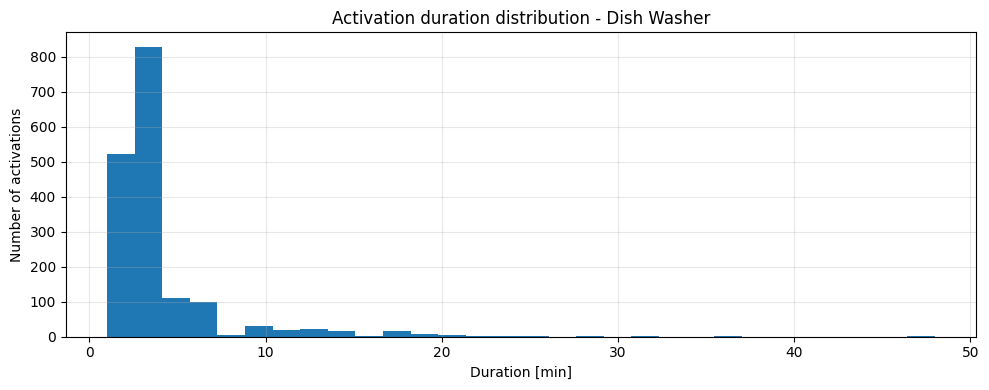

In [22]:
plt.figure(figsize=(10, 4))
plt.hist(activations_df["duration_min"], bins=30)
plt.xlabel("Duration [min]")
plt.ylabel("Number of activations")
plt.title(f"Activation duration distribution - {device_names[device_idx]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

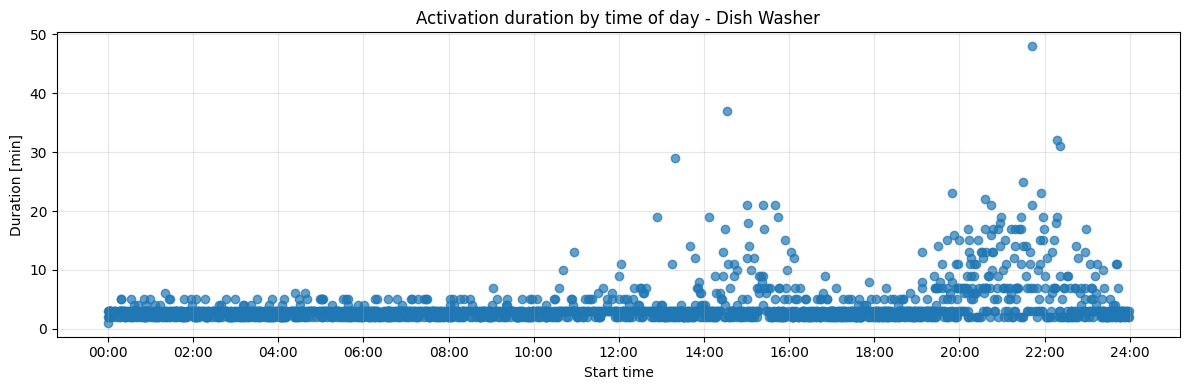

In [23]:
plt.figure(figsize=(12, 4))
plt.scatter(
    activations_df["start_minute_of_day"],
    activations_df["duration_min"],
    alpha=0.7
)

xticks = np.arange(0, 1441, 120)
plt.xticks(
    xticks,
    [f"{int(x//60):02d}:00" for x in xticks]
)

plt.xlabel("Start time")
plt.ylabel("Duration [min]")
plt.title(f"Activation duration by time of day - {device_names[device_idx]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()